In [ ]:
import avalanchers
import time

start = time.time()
path = "ISeeSnow/data/"
cases = {
    "CoulombOnly": {
        "friction_model": 0,
        "friction_coefficient": 0.4,
        "drag_coefficient": 0.0,
        "release": "release1HSField5m"
    },
    "IdealizedTopo": {
        "friction_model": 1,
        "friction_coefficient": 0.4,
        "drag_coefficient": 2000.0,
        "release": "release1HSField5m"
    },
    "RealTopo": {
        "friction_model": 1,
        "friction_coefficient": 0.2,
        "drag_coefficient": 2000.0,
        "release": "relWogField5m"
    }
}

sim = avalanchers.PySimulation.new()
for example_case in list(cases.keys()):
# for example_case in ["RealTopo"]:
    print(f"Running simulation for case: {example_case}")
    settings = {
        # mandatory: path to the DEM, currently only custom encoded png files are supported
        # optional, if not provided, a simple algorithm will be used to determine release areas based on the DEM
        "dem_path": f"{path}{example_case}/Inputs/DEM_{example_case}.asc",
        "release_areas_path": f"{path}{example_case}/Inputs/{cases[example_case]['release']}.asc",
        
        "max_steps": 5000,
        "batch_compute_steps": 300,
        "sim_model": "3d-depth-averaged",
        "released_particles_per_cell": 8,
        "friction_model": cases[example_case]["friction_model"],
        "density": 200.0,
        "friction_coefficient": cases[example_case]["friction_coefficient"],
        "drag_coefficient": cases[example_case]["drag_coefficient"],
        "cfl": 0.9,
        "min_slope_angle": 28.0,
        "max_slope_angle": 50.0,
        "release_min_elevation": 1500.0,
        "velocity_threshold": 0.1,
        "roughness_threshold": 0.01,
        "enable_curvature": True,
        "enable_particle_interaction": True,
        "enable_entrainment": True,
    }
    sim.create(settings)
    
    # sim.create_example(r"C:\git\AvalancheSim-WebGPU\data\avaframe\avaWog.png")

    sim.run()
    output = f"{path}{example_case}/Outputs_{example_case}/release1HS_null_03{example_case}_null_avalanchers"
    sim.write_asc("peak_velocity", f"{output}_pfv.asc")
    sim.write_asc("peak_flow_thickness", f"{output}_pft.asc")
    # peak_flow_thickness = sim.fetch_peak_flow_thickness()
    # avalanchers.plot2d(sim, "peak_velocity", title=f"Peak Velocity for {example_case}")

end = time.time()

print(f"Execution time without plotting: {end - start:.2f} seconds")

Running simulation for case: CoulombOnly
Running simulation for case: IdealizedTopo
Running simulation for case: RealTopo
Execution time without plotting: 5.00 seconds


CoulombOnly: n = 10 reference models: TITAN2Dv420, samosat, avaflow, com1DFA, Gerris, INRAEaval, minVoellmyv2, openFOAMmu, TRENT2D, faSavageHutterFoamGamma
IdealizedTopo: n = 9 reference models: TITAN2Dv420, samosat, avaflow, com1DFA, Gerris, INRAEaval, minVoellmyv2, TRENT2D, faSavageHutterFoamGamma
RealTopo: n = 8 reference models: INRAEaval, samosat, avaflow, com1DFA, Gerris, minVoellmyv2, TRENT2D, faSavageHutterFoamGamma


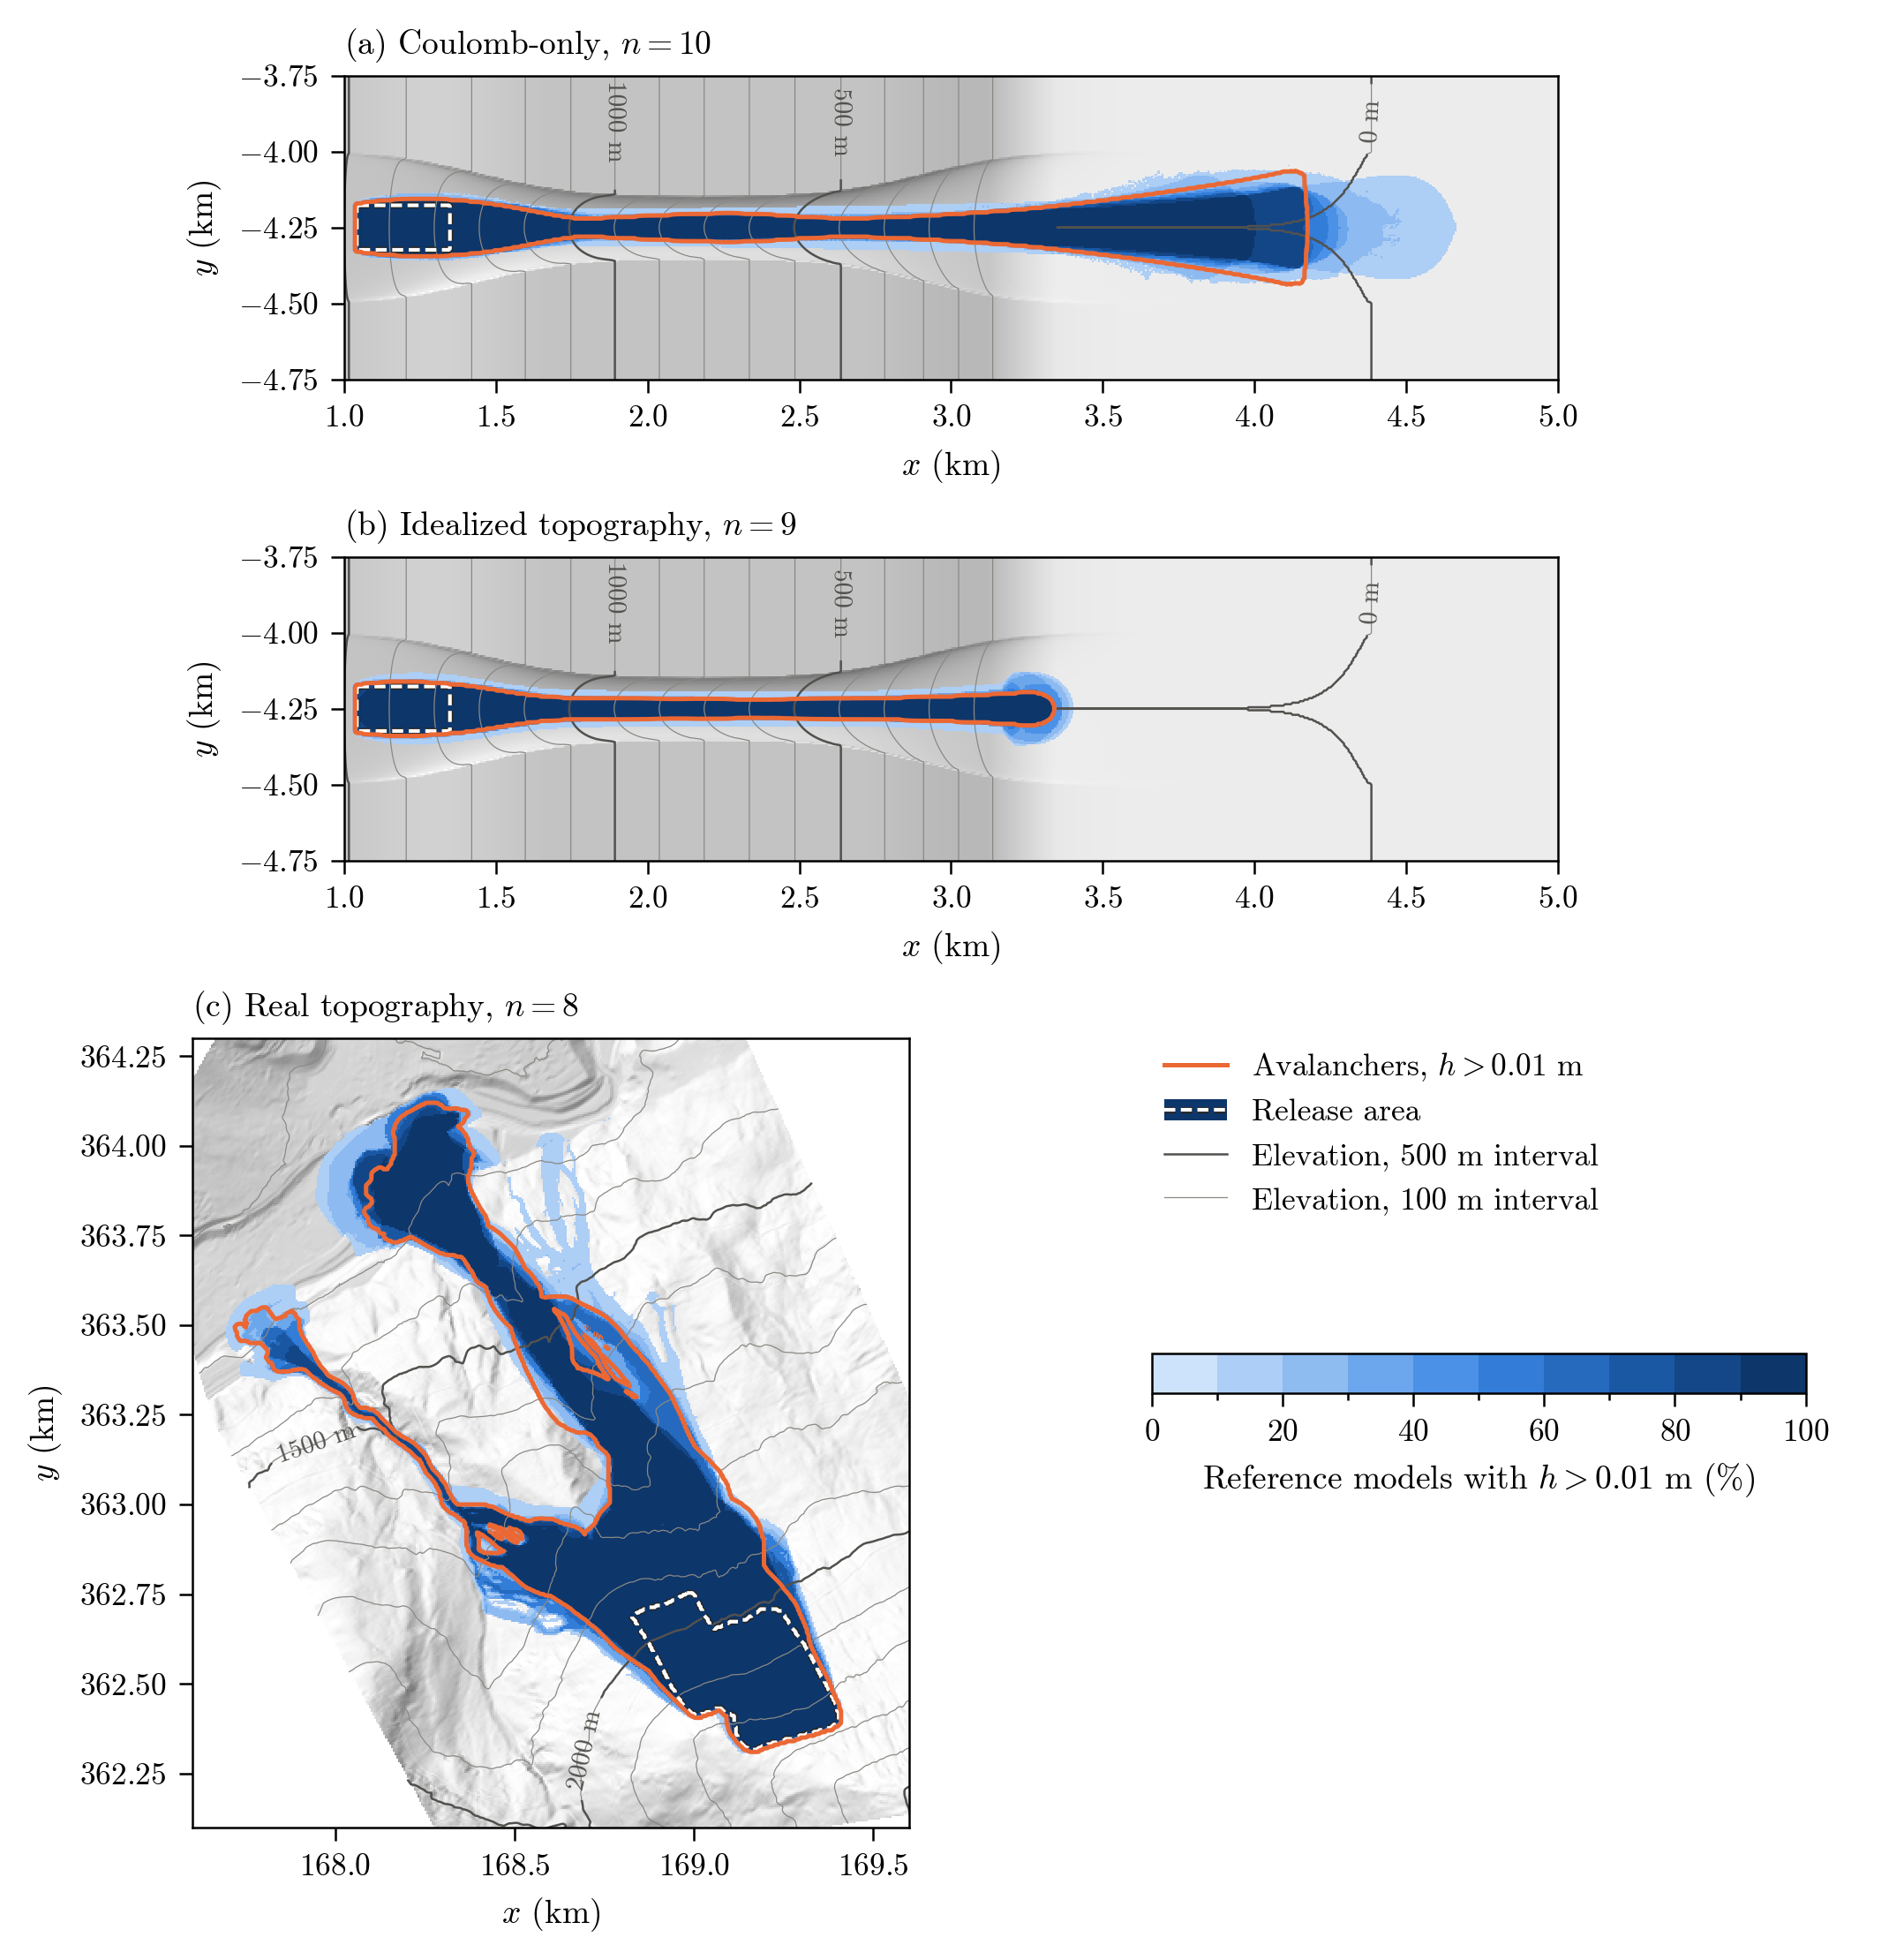

In [11]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib import patheffects
from matplotlib.colors import BoundaryNorm, LightSource, LinearSegmentedColormap
from matplotlib.legend_handler import HandlerTuple
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# The cmr10 font has odd timestamps, which fontTools reports when embedding it in a PDF
logging.getLogger("fontTools.ttLib.tables._h_e_a_d").setLevel(logging.ERROR)

DATA_DIR = Path("ISeeSnow/data")
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

THRESHOLD = 0.01  # flow thickness (m) that defines the footprint of a simulation
EXCLUDED_MODELS = ("flo2d",)  # different model type, not part of the reference ensemble
CM = 1 / 2.54
TEXT_WIDTH = 18 * CM  # \textwidth of the thesis

CASES = {
    "CoulombOnly": {
        "label": "Coulomb-only",
        "release": "release1HSField5m",
        "color": "#2a78d6",
        "marker": "o",
        "linestyle": "-",
    },
    "IdealizedTopo": {
        "label": "Idealized topography",
        "release": "release1HSField5m",
        "color": "#eb6834",
        "marker": "s",
        "linestyle": "--",
    },
    "RealTopo": {
        "label": "Real topography",
        "release": "relWogField5m",
        "color": "#1baf7a",
        "marker": "^",
        "linestyle": "-.",
    },
}

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["cmr10"],  # Computer Modern, the font of the thesis
    "mathtext.fontset": "cm",
    "axes.formatter.use_mathtext": True,
    "axes.unicode_minus": False,
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "legend.fontsize": 8.5,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "pdf.fonttype": 42,
    "savefig.dpi": 300,
})


def read_on_grid(path, transform, shape):
    """Samples a raster at the cell centers of the target grid, 0 outside of it.

    The submitted grids differ in origin and size, so they have to be matched by
    their georeference and not by their array index.
    """
    with rasterio.open(path) as source:
        data = np.nan_to_num(source.read(1, masked=True).filled(0.0).astype(float))
        to_source = ~source.transform
    rows, cols = np.indices(shape)
    x, y = transform * (cols + 0.5, rows + 0.5)
    source_col, source_row = to_source * (x, y)
    source_col = np.floor(source_col).astype(int)
    source_row = np.floor(source_row).astype(int)
    inside = (
        (source_row >= 0)
        & (source_row < data.shape[0])
        & (source_col >= 0)
        & (source_col < data.shape[1])
    )
    result = np.zeros(shape)
    result[inside] = data[source_row[inside], source_col[inside]]
    return result


def model_name(path):
    return path.stem.removesuffix("_pft").split("_")[-1]


def load_case(case):
    inputs = DATA_DIR / case / "Inputs"
    outputs = DATA_DIR / case / f"Outputs_{case}"
    with rasterio.open(inputs / f"DEM_{case}.asc") as source:
        dem = source.read(1, masked=True).filled(np.nan).astype(float)
        transform = source.transform

    shape = dem.shape
    avalanchers = None
    reference = {}
    for path in sorted(outputs.glob("*_pft.asc")):
        if "avalanchers" in path.name:
            avalanchers = read_on_grid(path, transform, shape)
        elif not any(model in path.name for model in EXCLUDED_MODELS):
            reference[model_name(path)] = read_on_grid(path, transform, shape)

    if avalanchers is None:
        raise FileNotFoundError(f"No Avalanchers result in {outputs}, run the simulation cell first")

    # Number of reference models whose footprint contains each cell
    count = np.sum([pft > THRESHOLD for pft in reference.values()], axis=0)
    x = transform.c + (np.arange(shape[1]) + 0.5) * transform.a
    y = transform.f + (np.arange(shape[0]) + 0.5) * transform.e
    return {
        "dem": dem,
        "x": x,
        "y": y,
        "release": read_on_grid(inputs / f"{CASES[case]['release']}.asc", transform, shape),
        "avalanchers": avalanchers,
        "reference": reference,
        "count": count,
        "n": len(reference),
    }


results = {case: load_case(case) for case in CASES}
for case, result in results.items():
    print(f"{case}: n = {result['n']} reference models: {', '.join(result['reference'])}")

# Blue ramp, one color per 10 % class
agreement_cmap = LinearSegmentedColormap.from_list(
    "agreement", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"], N=10
)
agreement_norm = BoundaryNorm(np.arange(0, 101, 10), agreement_cmap.N, clip=True)
OUTLINE_COLOR = "#eb6834"
# White for the dark flow, the dark edge for the legend and print
RELEASE_STYLE = {
    "color": "white",
    "linewidth": 1.0,
    "linestyle": (0, (3, 1.5)),
    "path_effects": [patheffects.withStroke(linewidth=1.7, foreground="#26251f")],
}


def row_crossings(contours, result, row_y, x_start):
    """Points where the contours cross the row at `row_y` (km)."""
    row = np.argmin(np.abs(result["y"] / 1000 - row_y))
    profile = result["dem"][row]
    x_km = result["x"] / 1000
    points = []
    for level in contours.levels:
        crossings = np.nonzero(np.diff(np.sign(profile - level)))[0]
        points += [(x_km[i], row_y) for i in crossings if x_km[i] > x_start]
    return points


def plot_case(ax, case, limits, label_row=None, label_points=()):
    result = results[case]
    x_km, y_km = result["x"] / 1000, result["y"] / 1000
    agreement = 100 * result["count"] / result["n"]
    cell = abs(result["x"][1] - result["x"][0])
    half_cell = cell / 2000
    extent = [
        x_km[0] - half_cell,
        x_km[-1] + half_cell,
        y_km[-1] - half_cell,
        y_km[0] + half_cell,
    ]
    ax.imshow(
        LightSource(azdeg=315, altdeg=45).hillshade(result["dem"], dx=cell, dy=cell),
        extent=extent,
        origin="upper",
        cmap="gray",
        vmin=-0.8,  # keeps the relief light, so lines and labels stay readable
        vmax=1,
        interpolation="nearest",
    )
    # Opaque on top of the relief, so the colors match the colorbar
    image = ax.imshow(
        np.ma.masked_equal(agreement, 0),
        extent=extent,
        origin="upper",
        cmap=agreement_cmap,
        norm=agreement_norm,
        interpolation="nearest",
    )
    elevation_range = np.arange(0, 5000, 100)
    ax.contour(
        x_km, y_km, result["dem"],
        levels=elevation_range, colors="#8a8984", linewidths=0.3,
    )
    major = ax.contour(
        x_km, y_km, result["dem"],
        levels=elevation_range[::5], colors="#52514e", linewidths=0.6,
    )
    if label_row is not None:
        label_points = row_crossings(major, result, label_row, limits[0][0] + 0.2)
    # Placed by hand, as automatic labels end up below the flow or the map edge
    ax.clabel(major, manual=label_points, fontsize=7, fmt="%d m", inline_spacing=2)
    release = ax.contour(
        x_km, y_km, result["release"],
        levels=[0.5],
        colors=RELEASE_STYLE["color"],
        linewidths=RELEASE_STYLE["linewidth"],
        linestyles=[RELEASE_STYLE["linestyle"]],
    )
    release.set_path_effects(RELEASE_STYLE["path_effects"])
    ax.contour(
        x_km, y_km, result["avalanchers"],
        levels=[THRESHOLD], colors=OUTLINE_COLOR, linewidths=1.2,
    )
    ax.set(xlim=limits[0], ylim=limits[1], xlabel="$x$ (km)", ylabel="$y$ (km)")
    ax.set_aspect("equal")
    return image


# The two idealized cases share their topography, so they share the map extent.
strip_limits = ((1.0, 5.0), (-4.75, -3.75))
real_limits = ((167.6, 169.6), (362.1, 364.3))

fig = plt.figure(figsize=(TEXT_WIDTH, 18.5 * CM), dpi=300, layout="constrained")
grid = fig.add_gridspec(3, 2, height_ratios=[1, 1, 2.6], width_ratios=[1.45, 1])
ax_coulomb = fig.add_subplot(grid[0, :])
ax_idealized = fig.add_subplot(grid[1, :])
ax_real = fig.add_subplot(grid[2, 0])
ax_key = fig.add_subplot(grid[2, 1])
ax_key.axis("off")

image = plot_case(ax_coulomb, "CoulombOnly", strip_limits, label_row=-3.9)
plot_case(ax_idealized, "IdealizedTopo", strip_limits, label_row=-3.9)
plot_case(ax_real, "RealTopo", real_limits, label_points=[(167.95, 363.16), (168.7, 362.3)])
for ax, case, letter in zip(
    (ax_coulomb, ax_idealized, ax_real), CASES, "abc"
):
    ax.set_title(
        f"({letter}) {CASES[case]['label']}, $n = {results[case]['n']}$", loc="left"
    )

key = {
    f"Avalanchers, $h > {THRESHOLD}$ m": Line2D([], [], color=OUTLINE_COLOR, linewidth=1.2),
    # Dark bar below the dashes, as the outline sits on the flow in the maps
    "Release area": (Patch(facecolor="#0d366b"), Line2D([], [], **RELEASE_STYLE)),
    "Elevation, 500 m interval": Line2D([], [], color="#52514e", linewidth=0.6),
    "Elevation, 100 m interval": Line2D([], [], color="#8a8984", linewidth=0.3),
}
ax_key.legend(
    list(key.values()),
    list(key),
    handler_map={tuple: HandlerTuple(ndivide=1, pad=0)},
    loc="upper left",
    frameon=False,
    borderaxespad=0,
)
colorbar_ax = ax_key.inset_axes([0.0, 0.55, 0.9, 0.05])
colorbar = fig.colorbar(
    image, cax=colorbar_ax, orientation="horizontal", ticks=np.arange(0, 101, 20)
)
colorbar.set_label(f"Reference models with $h > {THRESHOLD}$ m (%)")
colorbar.outline.set_linewidth(0.6)

for extension in ("pdf", "png"):
    fig.savefig(FIGURE_DIR / f"iseesnow_model_agreement.{extension}", dpi=600)
plt.show()


Agreement of simulated footprints for the ISeeSnow test cases (Wirbel et al., 2026): (a) Coulomb-only, (b) idealized topography, (c) real topography. Colours show the share of the n reference models with peak flow thickness h > 0.01 m, in classes of 10%. Cells reached by no reference model show the hillshade of the DEM (light from azimuth 315°, altitude 45°); white areas in (c) lie outside the DEM. The orange line is the Avalanchers footprint for the same threshold, and the white dashed line is the release area. Thin and thick grey lines are elevation contours at 100 m and 500 m intervals. All grids were sampled onto the 5 m DEM grid. Coordinates in (a) and (b) are those of the benchmark grid; in (c) they are MGI Austria Lambert. The reference models are INRAEaval, TRENT2D, avaflow, com1DFA, Gerris, minVoellmyv2, samosat and faSavageHutterFoamGamma, plus TITAN2D in (a, b) and openFOAMmu in (a).

case    CoulombOnly  IdealizedTopo  RealTopo
models                                      
1             0.548          0.519     0.635
2             0.716          0.714     0.769
3             0.816          0.756     0.822
4             0.827          0.816     0.828
5             0.842          0.879     0.833
6             0.855          0.910     0.784
7             0.851          0.928     0.757
8             0.838          0.941     0.708
9             0.710          0.916       NaN
10            0.670            NaN       NaN


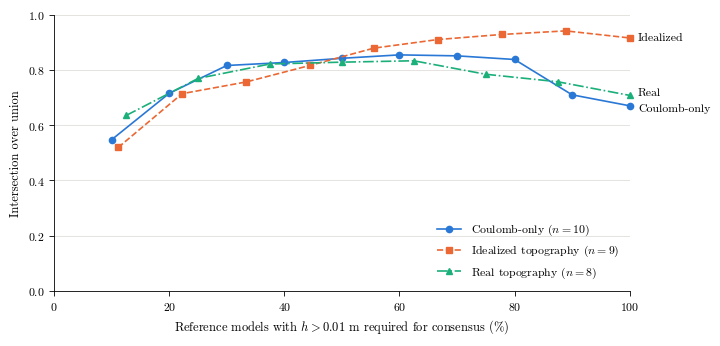

In [12]:
import pandas as pd


def consensus_iou(result):
    """IoU of the Avalanchers footprint and the footprint shared by >= k models.

    The share of models can only take the values k / n, so these are the levels
    evaluated; any threshold in between selects the same cells. Release cells
    are left out, as every simulation covers them from the start.
    """
    outside_release = result["release"] <= 0
    footprint = (result["avalanchers"] > THRESHOLD) & outside_release
    rows = []
    for k in range(1, result["n"] + 1):
        consensus = (result["count"] >= k) & outside_release
        union = np.logical_or(footprint, consensus).sum()
        intersection = np.logical_and(footprint, consensus).sum()
        rows.append({
            "models": k,
            "share": 100 * k / result["n"],
            "iou": intersection / union,
        })
    return pd.DataFrame(rows)


ious = {case: consensus_iou(result) for case, result in results.items()}
table = pd.concat(ious, names=["case"]).droplevel(1).reset_index()
table.to_csv(FIGURE_DIR / "iseesnow_consensus_iou.csv", index=False, float_format="%.4f")
print(table.pivot(index="models", columns="case", values="iou").round(3).to_string())

# Points of the end labels, shifted where two lines end close to each other
LABEL_OFFSETS = {"CoulombOnly": (6, -2), "IdealizedTopo": (6, 0), "RealTopo": (6, 2)}

fig, ax = plt.subplots(figsize=(TEXT_WIDTH, 8.5 * CM), layout="constrained")
for case, iou in ious.items():
    style = CASES[case]
    ax.plot(
        iou["share"],
        iou["iou"],
        color=style["color"],
        marker=style["marker"],
        linestyle=style["linestyle"],
        linewidth=1.2,
        markersize=4.5,
        label=f"{style['label']} ($n = {results[case]['n']}$)",
        clip_on=False,
    )
    ax.annotate(
        style["label"].split()[0],
        xy=(iou["share"].iloc[-1], iou["iou"].iloc[-1]),
        xytext=LABEL_OFFSETS[case],
        textcoords="offset points",
        va="center",
        fontsize=8.5,
    )

ax.set(
    xlim=(0, 100),
    ylim=(0, 1),
    xlabel=f"Reference models with $h > {THRESHOLD}$ m required for consensus (%)",
    ylabel="Intersection over union",
)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.grid(axis="y", color="#d9d8d3", linewidth=0.5)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False)

for extension in ("pdf", "png"):
    fig.savefig(FIGURE_DIR / f"iseesnow_consensus_iou.{extension}")
plt.show()

IoU plot. Intersection over union (IoU) between the Avalanchers footprint and the consensus footprint of the reference models, as a function of the share k/n of the n reference models required for consensus. Footprints are the cells with peak flow thickness h > 0.01 m on the 5 m DEM grid, and a cell belongs to the consensus footprint if at least k of the n models reach it. Cells of the release area are not counted. Markers show all possible levels k/n. Lines show the Coulomb-only (solid, circles, n = 10), idealized topography (dashed, squares, n = 9) and real topography (dash-dotted, triangles, n = 8) cases. Reference models as in Fig. xx.

In [23]:
def latex_table():
    values = table.pivot(index="models", columns="case", values="iou")[list(CASES)]
    header = ["$k$"] + [f"{CASES[case]['label']} ($n = {results[case]['n']}$)" for case in CASES]
    rows = [
        " & ".join([str(k)] + ["--" if np.isnan(v) else f"{v:.3f}" for v in row]) + r" \\"
        for k, row in zip(values.index, values.to_numpy())
    ]
    return "\n".join([
        r"\begin{table}[!htb]",
        r"\centering",
        r"\begin{footnotesize}",
        r"\begin{tabular}{cccc}",
        r"\hline",
        r"\hline",
        " & ".join(header) + r" \\",
        r"\hline",
        *rows,
        r"\hline",
        r"\end{tabular}",
        r"\end{footnotesize}",
        r"\caption{Intersection over union (IoU) between the Avalanchers footprint and the "
        r"footprint shared by at least $k$ of the $n$ reference models, for peak flow thickness "
        rf"$h > {THRESHOLD}$~m. Cells of the release area are not counted. Dashes mark levels "
        r"above $n$.}",
        r"\label{tab:iseesnow_iou}",
        r"\end{table}",
    ])


print(latex_table())

\begin{table}[!htb]
\centering
\begin{footnotesize}
\begin{tabular}{cccc}
\hline
\hline
$k$ & Coulomb-only ($n = 10$) & Idealized topography ($n = 9$) & Real topography ($n = 8$) \\
\hline
1 & 0.542 & 0.518 & 0.631 \\
2 & 0.713 & 0.712 & 0.760 \\
3 & 0.816 & 0.754 & 0.810 \\
4 & 0.830 & 0.814 & 0.826 \\
5 & 0.846 & 0.876 & 0.839 \\
6 & 0.860 & 0.908 & 0.788 \\
7 & 0.857 & 0.927 & 0.763 \\
8 & 0.845 & 0.940 & 0.714 \\
9 & 0.718 & 0.916 & -- \\
10 & 0.678 & -- & -- \\
\hline
\end{tabular}
\end{footnotesize}
\caption{Intersection over union (IoU) between the Avalanchers footprint and the footprint shared by at least $k$ of the $n$ reference models, for peak flow thickness $h > 0.01$~m. Cells of the release area are not counted. Dashes mark levels above $n$.}
\label{tab:iseesnow_iou}
\end{table}


Text(0.5, 0.98, 'Avalanchers - Other models mean flow thickness')

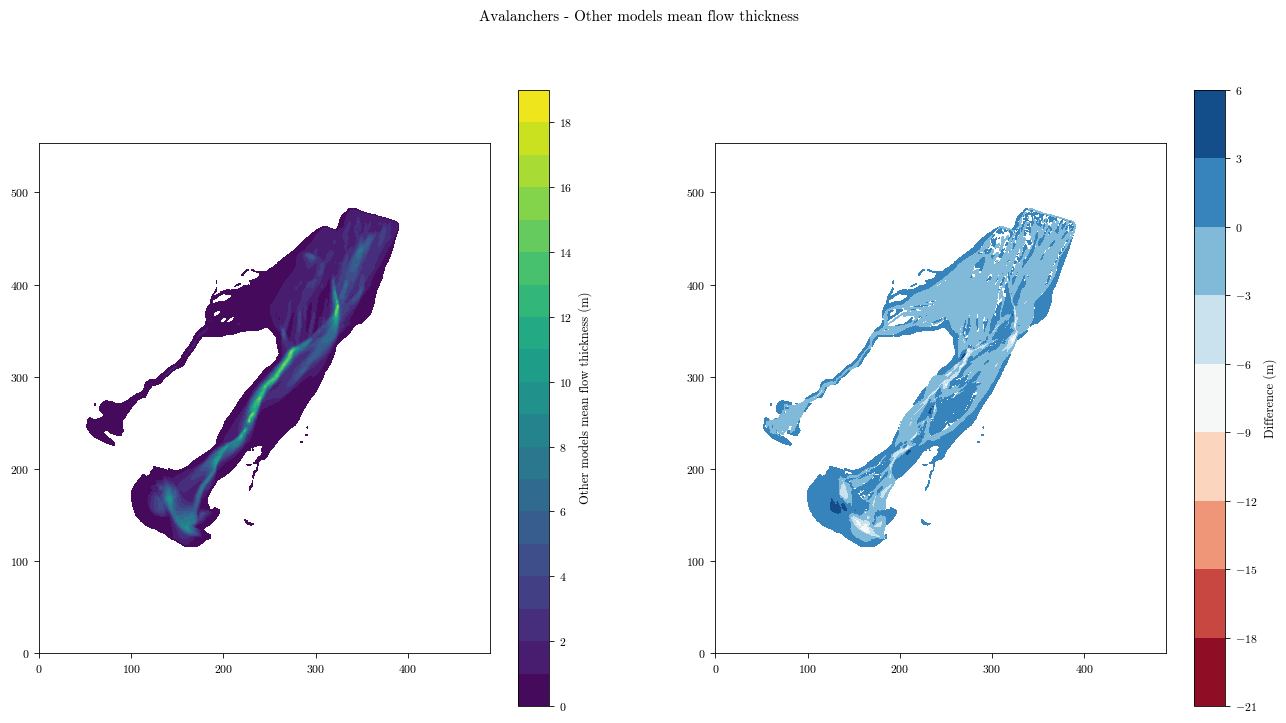

In [24]:
pfts = list(results["RealTopo"]["reference"].values())
avalanchers_pft = results["RealTopo"]["avalanchers"]
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
pft_mean = np.mean(pfts, axis=0)
pft_mean_plot = np.copy(pft_mean)
pft_mean_plot[pft_mean_plot < 0.01] = np.nan
cb = axes[0].contourf(pft_mean_plot, cmap="viridis", levels=range(0, 20, 1))
plt.colorbar(cb, ax=axes[0], label="Other models mean flow thickness (m)")
axes[0].set_aspect("equal")
diff = pft_mean - avalanchers_pft
diff[(diff < 0.01) & (diff > -0.1)] = np.nan
cbr = axes[1].contourf(diff, cmap="RdBu")
plt.colorbar(cbr, ax=axes[1], label="Difference (m)")
axes[1].set_aspect("equal")
plt.suptitle("Avalanchers - Other models mean flow thickness")